# 02 — Task 2: KDEF dataset study (15 %)

* KDEF frontal images, preprocessed to the FER format with the kit's procedure
  (Haar face crop with 20 % margin → gray → 48×48), see notebook 00.
* **Subject-independent evaluation:** the official 80/20 split by identity (56 train / 14 test
  subjects, series A and B of a person always in the same split) — no person appears in both.
* The same classifiers and features as on FER2013 are re-trained (the best FER feature set is
  highlighted, but the full grid is filled so the tables have the same layout as Task 1).
* There is no validation split, so hyper-parameters are tuned with **5-fold GroupKFold over the
  training subjects** (macro-F1).
* Extra studies: **gray vs RGB** (KDEF is the only dataset with colour) and the same
  gray / CLAHE / black-and-white / edges variants as on FER.

In [1]:
# Common setup + evaluation helpers (identical in every notebook of the project)
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedShuffleSplit

sys.path.insert(0, str(Path.cwd()))
try:
    from src import features as F
except ImportError:  # fuzzy environment (no OpenCV/dlib): only cached features are used there
    from types import SimpleNamespace
    F = SimpleNamespace(EMOTIONS=["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"],
                        CACHE_DIR=Path("data") / "cache")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# SMOKE=1 (environment variable) runs everything on small subsets with reduced grids, to
# check the notebook end-to-end in minutes. The delivered results use SMOKE=0 (default).
SMOKE = os.environ.get("SMOKE", "0") == "1"
SEED = 42
N_JOBS = -1
EMO = F.EMOTIONS
RESULTS_DIR, FIG_DIR, MODEL_DIR = Path("results"), Path("figures"), Path("models")
for d in (RESULTS_DIR, FIG_DIR, MODEL_DIR, F.CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
print(f"SMOKE={SMOKE}")


def metrics(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "bal_acc": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=range(7), zero_division=0)}


def per_class_f1(y_true, y_pred):
    return pd.Series(f1_score(y_true, y_pred, average=None, labels=range(7), zero_division=0), index=EMO)


_RESULTS = {}


def reset_results(task):
    """Start a fresh results/<task>.csv for this run of the notebook."""
    _RESULTS[task] = []
    (RESULTS_DIR / f"{task}.csv").unlink(missing_ok=True)


def log_result(task, y_true, y_pred, **info):
    """Append one evaluation row (fixed schema) to results/<task>.csv and return it."""
    row = {**info, **{k: round(v, 4) for k, v in metrics(y_true, y_pred).items()}, "n": len(y_true)}
    _RESULTS.setdefault(task, []).append(row)
    pd.DataFrame(_RESULTS[task]).to_csv(RESULTS_DIR / f"{task}.csv", index=False)
    return row


def fixed_table(df, index, columns, value, index_order, column_order):
    """Pivot to a table with a FIXED row/column layout (same x and y in every task)."""
    t = df.pivot_table(index=index, columns=columns, values=value, aggfunc="first")
    return t.reindex(index=index_order, columns=column_order)


def save_table(df, name, float_format="%.3f"):
    """Save a table as CSV and as a LaTeX tabular (pasted into report/*.md)."""
    df.to_csv(RESULTS_DIR / f"{name}.csv")
    with open(RESULTS_DIR / f"{name}.tex", "w", encoding="utf-8") as f:
        f.write(df.to_latex(float_format=float_format, na_rep="--"))
    return df


def plot_cm(y_true, y_pred, title="", ax=None, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=range(7), normalize="true" if normalize else None)
    ax = ax or plt.subplots(figsize=(4.2, 3.6))[1]
    sns.heatmap(cm, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False,
                xticklabels=[e[:3] for e in EMO], yticklabels=[e[:3] for e in EMO], ax=ax,
                vmin=0, vmax=1 if normalize else None, annot_kws={"size": 7})
    ax.set_title(title, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    return ax


def plot_cm_grid(items, fname, ncols=4):
    """items: list of (title, y_true, y_pred). Saved in figures/ for the report appendix."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.7 * nrows), squeeze=False)
    for ax, (title, yt, yp) in zip(axes.ravel(), items):
        plot_cm(yt, yp, title, ax=ax)
    for ax in axes.ravel()[len(items):]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


def stratified_subset(y, n, seed=SEED):
    """Indices of a stratified random subset of size n (all indices if n >= len(y))."""
    if n is None or n >= len(y):
        return np.arange(len(y))
    sss = StratifiedShuffleSplit(n_splits=1, train_size=n, random_state=seed)
    return np.sort(next(sss.split(np.zeros(len(y)), y))[0])


def scores(model, X):
    """Class scores for confidence analyses (predict_proba, else softmax(decision_function))."""
    if hasattr(model, "predict_proba"):
        try:
            return model.predict_proba(X)
        except AttributeError:
            pass
    d = model.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def save_bundle(name, model, spec, **extra):
    """Persist a FITTED model together with the feature spec needed to use it (demo, other tasks)."""
    bundle = {"model": model, "spec": spec, "labels": EMO, **extra}
    joblib.dump(bundle, MODEL_DIR / f"{name}.pkl", compress=3)
    print(f"saved models/{name}.pkl")


def show_images(imgs, titles=None, ncols=8, size=1.5, fname=None, suptitle=None, cmap="gray"):
    nrows = int(np.ceil(len(imgs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 1.15 * nrows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i], cmap=None if imgs[i].ndim == 3 else cmap, vmin=0, vmax=255)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname)
    plt.show()

SMOKE=False


In [2]:
# Classifiers, feature sets and the tuning protocol (shared by notebooks 01, 02, 03, 05)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit, GroupKFold
from sklearn.base import clone
from src.gpu_svm import GPUKernelSVC, device, MAX_KERNEL_N

# The RBF-SVM is GPUKernelSVC: the same libsvm solver as SVC(kernel="rbf"), but the kernel matrix is
# computed with PyTorch on the GPU (CUDA) — identical predictions, ~30x faster (see src/gpu_svm.py).
print("kernel computations on:", device())
MODELS = ["LR", "SVM", "RF"]               # fixed row order of every result grid
FEATURES = ["HOG", "LM", "PCA", "HOG+LM"]   # fixed column order of every result grid
FEATURE_BLOCKS = {"HOG": ["hog"], "LM": ["lm"], "PCA": ["pix"], "HOG+LM": ["hog", "lm"]}
N_TREES = 100 if SMOKE else 300
# one GPU: run SVM grid candidates one after the other (each holds an n x n kernel matrix)
SVM_JOBS = 1 if device() == "cuda" else 4


def base_estimator(model, n_jobs=1):
    if model == "LR":
        return LogisticRegression(max_iter=3000, random_state=SEED)
    if model == "SVM":
        return GPUKernelSVC(gamma="scale", cache_size=2000, random_state=SEED)
    if model == "RF":
        return RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", n_jobs=n_jobs, random_state=SEED)
    raise ValueError(model)


def make_pipeline(model, feature, n_jobs=1):
    """StandardScaler -> [PCA (eigenfaces, only for raw pixels)] -> classifier."""
    steps = [("scaler", StandardScaler())]
    if feature == "PCA":
        steps.append(("pca", PCA(n_components=100, whiten=True, random_state=SEED)))
    steps.append(("clf", base_estimator(model, n_jobs)))
    return Pipeline(steps)


if SMOKE:
    GRIDS = {"LR": {"clf__C": [0.1, 1.0], "clf__class_weight": ["balanced"]},
             "SVM": {"clf__C": [1, 10], "clf__class_weight": ["balanced"]},
             "RF": {"clf__max_depth": [None], "clf__class_weight": [None, "balanced_subsample"]}}
    PCA_GRID = {"pca__n_components": [60]}
else:
    GRIDS = {"LR": {"clf__C": [0.01, 0.1, 1.0], "clf__class_weight": [None, "balanced"]},
             "SVM": {"clf__C": [1, 3, 10], "clf__class_weight": [None, "balanced"]},
             "RF": {"clf__max_depth": [None, 25], "clf__min_samples_leaf": [1, 3],
                    "clf__class_weight": [None, "balanced_subsample"]}}
    PCA_GRID = {"pca__n_components": [60, 120]}


def param_grid(model, feature):
    return {**GRIDS[model], **(PCA_GRID if feature == "PCA" else {})}


def tune_predefined(model, feature, X_tr, y_tr, X_va, y_va, n_search):
    """Grid search: fit on (a stratified subset of) Training, score macro-F1 on PublicTest."""
    idx = stratified_subset(y_tr, n_search)
    X = np.vstack([X_tr[idx], X_va]); y = np.concatenate([y_tr[idx], y_va])
    ps = PredefinedSplit(np.concatenate([-np.ones(len(idx)), np.zeros(len(y_va))]))
    gs = GridSearchCV(make_pipeline(model, feature), param_grid(model, feature),
                      scoring="f1_macro", cv=ps, n_jobs=SVM_JOBS if model == "SVM" else N_JOBS, refit=False)
    gs.fit(X, y)
    return gs.best_params_, gs.best_score_


def tune_groupkfold(model, feature, X, y, groups, n_splits=5):
    """Subject-independent CV (no validation split exists for KDEF)."""
    gs = GridSearchCV(make_pipeline(model, feature), param_grid(model, feature), scoring="f1_macro",
                      cv=GroupKFold(n_splits=n_splits), n_jobs=SVM_JOBS if model == "SVM" else N_JOBS, refit=False)
    gs.fit(X, y, groups=groups)
    std = gs.cv_results_["std_test_score"][gs.best_index_]
    return gs.best_params_, gs.best_score_, std


def fit_final(model, feature, params, X, y, sample_weight=None):
    pipe = make_pipeline(model, feature, n_jobs=N_JOBS).set_params(**params)
    fit_kw = {"clf__sample_weight": sample_weight} if sample_weight is not None else {}
    return pipe.fit(X, y, **fit_kw)

kernel computations on: cuda


In [3]:
# Cached datasets and features (written by 00_data_preparation.ipynb)
# Dataset keys: "fer_gray", "fer_aligned", "kdef_m0.0_gray" ... "kdef_m0.3_gray", "kdef_m0.2_rgb",
# "kdef_m0.2_gray_aligned". Splits: FER train/val/test, KDEF train/test.
import re
FEATURE_BLOCKS.update({"GEO": ["geo"]})
_DS = {}


def images(key, split):
    if key not in _DS:
        _DS[key] = dict(np.load(F.CACHE_DIR / f"{key}.npz", allow_pickle=True))
    return _DS[key][f"X_{split}"], _DS[key][f"y_{split}"]


def meta(key, field, split):
    images(key, split)
    return _DS[key][f"{field}_{split}"]


def crop_margin(key):
    """Crop margin of a dataset (KDEF keys encode it, e.g. 'kdef_m0.2_gray'; FER crops: 0)."""
    m = re.search(r"_m([0-9.]+)_", key)
    return float(m.group(1)) if m else 0.0


def landmarks(key, split, variant="gray"):
    X, _ = images(key, split)
    vt = "" if variant == "gray" else f"-{variant}"
    return F.cached(f"{key}{vt}_{split}_pts",
                    lambda: F.extract_landmarks(F.apply_variant(X, variant), margin=crop_margin(key)))


def features(key, split, feature, variant="gray", hog=None):
    """Feature matrix of a cached dataset split (computed once, then loaded from data/cache)."""
    if feature == "HOG+LM":
        return np.hstack([features(key, split, "HOG", variant, hog), features(key, split, "LM", variant)])
    X, _ = images(key, split)
    vt = "" if variant == "gray" else f"-{variant}"
    ht = "" if not hog else "_o{}c{}".format(hog["orientations"], hog["pixels_per_cell"][0])
    spec = {"variant": variant, "blocks": FEATURE_BLOCKS[feature], "hog": hog or {}}
    pts = landmarks(key, split, variant) if feature in ("LM", "GEO") else None
    return F.cached(f"{key}{vt}_{split}_{feature}{ht}", lambda: F.extract_feature_set(X, spec, pts=pts))


def spec_for(feature, variant="gray", hog=None, crop_margin=0.0):
    """Feature spec stored in a model bundle (lets demo_emotion.py rebuild the features)."""
    blocks = sum((FEATURE_BLOCKS[f] for f in feature.split("+")), [])
    return {"variant": variant, "blocks": blocks, "hog": hog or {}, "feature": feature, "crop_margin": crop_margin}

In [4]:
for t in ("task2_grid", "task2_color", "task2_preproc"):
    reset_results(t)
KEY = "kdef_m0.2_gray"
y_tr, y_te = images(KEY, "train")[1], images(KEY, "test")[1]
groups = meta(KEY, "subj", "train")
t1 = json.load(open(RESULTS_DIR / "task1_best.json"))
print("Task 1 best:", t1["model"], t1["feature"], "| best feature per classifier:", t1["best_feature_per_model"])
print(f"KDEF train {len(y_tr)} images / {len(set(groups))} subjects, test {len(y_te)} images / "
      f"{len(set(meta(KEY, 'subj', 'test')))} subjects")
KX = {f: (features(KEY, "train", f), features(KEY, "test", f)) for f in FEATURES}

Task 1 best: SVM HOG+LM | best feature per classifier: {'LR': 'HOG+LM', 'SVM': 'HOG+LM', 'RF': 'HOG+LM'}
KDEF train 784 images / 56 subjects, test 196 images / 14 subjects


## 1. Classifier × feature grid on KDEF

In [5]:
fitted, preds, best_params = {}, {}, {}
for model in MODELS:
    for feat in FEATURES:
        X_tr, X_te = KX[feat]
        params, cv_f1, cv_std = tune_groupkfold(model, feat, X_tr, y_tr, groups)
        pipe = fit_final(model, feat, params, X_tr, y_tr)
        p = pipe.predict(X_te)
        fitted[(model, feat)], preds[(model, feat)], best_params[(model, feat)] = pipe, p, params
        r = log_result("task2_grid", y_te, p, model=model, feature=feat, split="test",
                       cv_f1=round(cv_f1, 4), cv_std=round(cv_std, 4), params=json.dumps(params))
        print(f"{model:4s} {feat:7s} CV F1={cv_f1:.3f}±{cv_std:.3f}  test F1={r['macro_f1']:.3f}  {params}")

LR   HOG     CV F1=0.661±0.026  test F1=0.577  {'clf__C': 0.01, 'clf__class_weight': None}
LR   LM      CV F1=0.701±0.058  test F1=0.695  {'clf__C': 0.1, 'clf__class_weight': None}
LR   PCA     CV F1=0.706±0.052  test F1=0.689  {'clf__C': 0.01, 'clf__class_weight': None, 'pca__n_components': 120}
LR   HOG+LM  CV F1=0.721±0.042  test F1=0.637  {'clf__C': 0.01, 'clf__class_weight': None}
SVM  HOG     CV F1=0.660±0.042  test F1=0.609  {'clf__C': 3, 'clf__class_weight': None}
SVM  LM      CV F1=0.670±0.056  test F1=0.628  {'clf__C': 3, 'clf__class_weight': None}
SVM  PCA     CV F1=0.666±0.055  test F1=0.622  {'clf__C': 3, 'clf__class_weight': None, 'pca__n_components': 60}
SVM  HOG+LM  CV F1=0.710±0.052  test F1=0.622  {'clf__C': 3, 'clf__class_weight': None}
RF   HOG     CV F1=0.603±0.046  test F1=0.611  {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__min_samples_leaf': 1}
RF   LM      CV F1=0.626±0.057  test F1=0.587  {'clf__class_weight': 'balanced_subsample', 


KDEF test macro_f1


feature,HOG,LM,PCA,HOG+LM
model,,,,
LR,0.577,0.695,0.689,0.637
SVM,0.609,0.628,0.622,0.622
RF,0.611,0.586,0.583,0.662



KDEF test acc


feature,HOG,LM,PCA,HOG+LM
model,,,,
LR,0.571,0.709,0.694,0.638
SVM,0.602,0.643,0.633,0.628
RF,0.617,0.602,0.602,0.679



KDEF test bal_acc


feature,HOG,LM,PCA,HOG+LM
model,,,,
LR,0.571,0.709,0.694,0.638
SVM,0.602,0.643,0.633,0.628
RF,0.617,0.602,0.602,0.679



GroupKFold CV macro-F1 (train subjects)


feature,HOG,LM,PCA,HOG+LM
model,,,,
LR,0.661,0.701,0.706,0.721
SVM,0.660,0.670,0.666,0.710
RF,0.603,0.626,0.595,0.680



Column 'HOG+LM' is the best feature representation identified on FER2013.


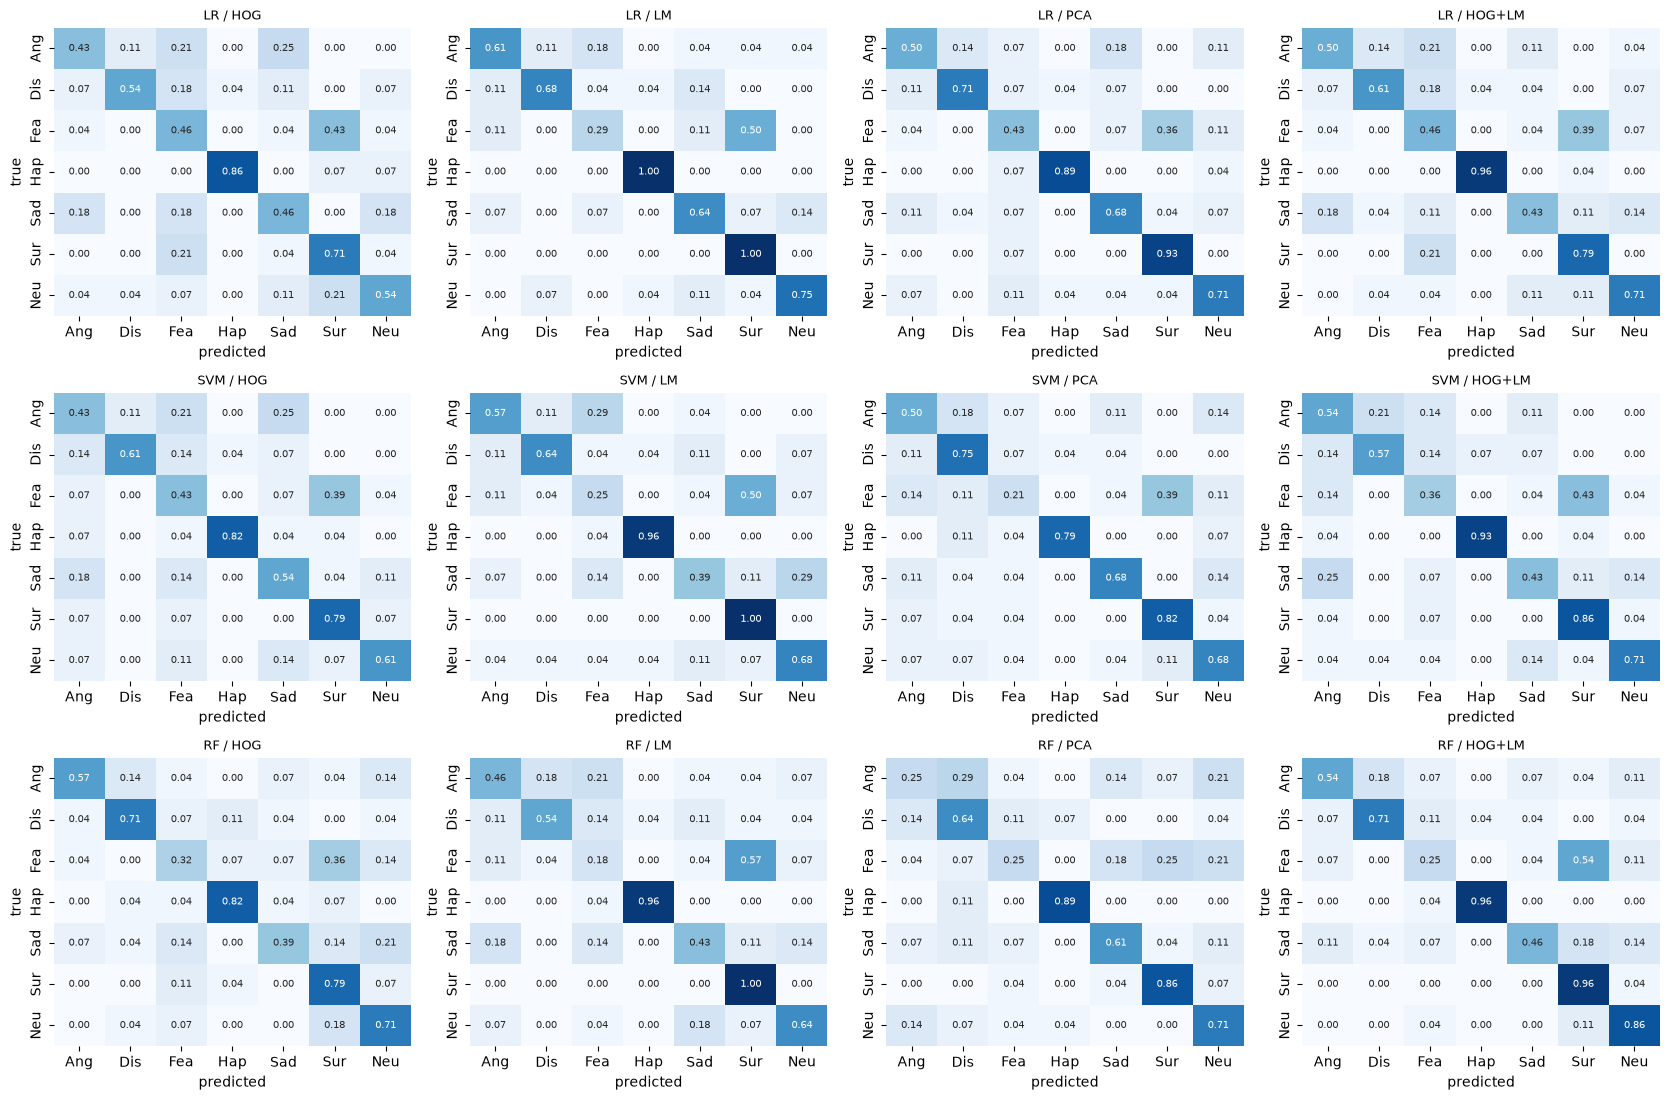

In [6]:
res = pd.read_csv(RESULTS_DIR / "task2_grid.csv")
tables = {m: save_table(fixed_table(res, "model", "feature", m, MODELS, FEATURES), f"task2_grid_test_{m}")
          for m in ("macro_f1", "acc", "bal_acc", "cv_f1")}
for m in ("macro_f1", "acc", "bal_acc", "cv_f1"):
    print(f"\nKDEF test {m}" if m != "cv_f1" else "\nGroupKFold CV macro-F1 (train subjects)")
    display(tables[m].round(3))
print(f"\nColumn '{t1['best_feature_overall']}' is the best feature representation identified on FER2013.")

plot_cm_grid([(f"{m} / {f}", y_te, preds[(m, f)]) for m in MODELS for f in FEATURES],
             "appendix_task2_confusion_matrices.png", ncols=4)

### Selection of the best KDEF configuration (on CV, not on test) + uncertainty
With only 196 test images (14 people) one test image is worth 0.5 % accuracy, so a bootstrap
95 % confidence interval of the test macro-F1 is reported as well.

In [7]:
BEST_MODEL, BEST_FEAT = tables["cv_f1"].stack().idxmax()
best = fitted[(BEST_MODEL, BEST_FEAT)]
p_best = preds[(BEST_MODEL, BEST_FEAT)]
rng = np.random.default_rng(SEED)
boot = [f1_score(y_te[i], p_best[i], average="macro") for i in (rng.integers(0, len(y_te), len(y_te)) for _ in range(1000))]
print(f"best KDEF configuration (CV): {BEST_MODEL} + {BEST_FEAT}  test macro-F1={f1_score(y_te, p_best, average='macro'):.3f} "
      f"(95% CI {np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f})")
for model in MODELS:
    feat = tables["cv_f1"].loc[model].idxmax()
    save_bundle(f"task2_{model}", fitted[(model, feat)], spec_for(feat, crop_margin=0.2), params=best_params[(model, feat)],
                trained_on="KDEF frontal train (56 subjects)", task="task2")
json.dump({"model": BEST_MODEL, "feature": BEST_FEAT, "params": best_params[(BEST_MODEL, BEST_FEAT)],
           "all_params": {f"{m}|{f}": p for (m, f), p in best_params.items()}},
          open(RESULTS_DIR / "task2_best.json", "w"), indent=2)

best KDEF configuration (CV): LR + HOG+LM  test macro-F1=0.637 (95% CI 0.570–0.697)
saved models/task2_LR.pkl
saved models/task2_SVM.pkl
saved models/task2_RF.pkl


## 2. Ranking changes between FER2013 and KDEF

In [8]:
fer_f1 = pd.read_csv(RESULTS_DIR / "task1_grid_test_macro_f1.csv", index_col=0).reindex(index=MODELS, columns=FEATURES)
kdef_f1 = tables["macro_f1"]
rank = pd.DataFrame({
    "FER rank (models)": fer_f1.mean(axis=1).rank(ascending=False).astype(int),
    "KDEF rank (models)": kdef_f1.mean(axis=1).rank(ascending=False).astype(int),
    "FER mean F1": fer_f1.mean(axis=1), "KDEF mean F1": kdef_f1.mean(axis=1)})
rank_f = pd.DataFrame({
    "FER rank (features)": fer_f1.mean(axis=0).rank(ascending=False).astype(int),
    "KDEF rank (features)": kdef_f1.mean(axis=0).rank(ascending=False).astype(int),
    "FER mean F1": fer_f1.mean(axis=0), "KDEF mean F1": kdef_f1.mean(axis=0)})
save_table(rank, "task2_rank_models"); save_table(rank_f, "task2_rank_features")
display(rank.round(3)); display(rank_f.round(3))
gap = save_table((kdef_f1 - fer_f1), "task2_minus_task1_macro_f1")
print("KDEF minus FER test macro-F1 (same layout):"); display(gap.round(3))

,FER rank (models),KDEF rank (models),FER mean F1,KDEF mean F1
model,,,,
LR,3,1,0.367,0.650
SVM,1,2,0.520,0.620
RF,2,3,0.466,0.611


,FER rank (features),KDEF rank (features),FER mean F1,KDEF mean F1
HOG,2,4,0.470,0.599
LM,3,2,0.420,0.637
PCA,4,3,0.415,0.631
HOG+LM,1,1,0.498,0.640


KDEF minus FER test macro-F1 (same layout):


feature,HOG,LM,PCA,HOG+LM
model,,,,
LR,0.192,0.320,0.409,0.211
SVM,0.041,0.208,0.117,0.038
RF,0.153,0.122,0.124,0.178


## 3. Per-emotion comparison FER vs KDEF
Same configuration (the best Task 1 configuration) trained and tested within each dataset.

,FER2013 (test),KDEF (test),difference
Angry,0.471,0.492,0.021
Disgust,0.644,0.627,-0.016
Fear,0.469,0.392,-0.077
Happy,0.777,0.929,0.152
Sad,0.447,0.480,0.033
Surprise,0.745,0.696,-0.049
Neutral,0.539,0.741,0.201


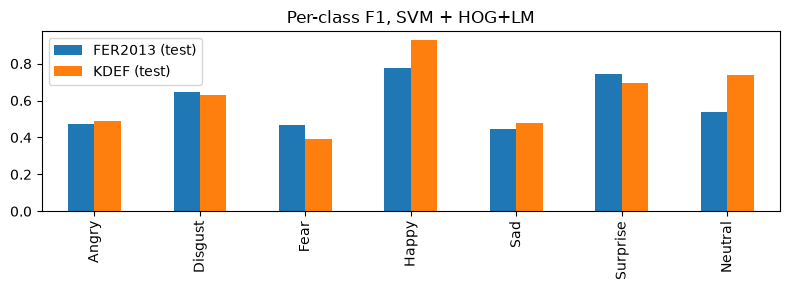

In [9]:
fer_res = pd.read_csv(RESULTS_DIR / "task1_per_class_f1.csv", index_col=0)
fer_col = f"{t1['model']}/{t1['best_feature_per_model'][t1['model']]}"
same = (t1["model"], t1["best_feature_per_model"][t1["model"]])
emo_cmp = pd.DataFrame({"FER2013 (test)": fer_res[fer_col], "KDEF (test)": per_class_f1(y_te, preds[same])})
emo_cmp["difference"] = emo_cmp["KDEF (test)"] - emo_cmp["FER2013 (test)"]
save_table(emo_cmp, "task2_per_class_fer_vs_kdef"); display(emo_cmp.round(3))
emo_cmp[["FER2013 (test)", "KDEF (test)"]].plot.bar(figsize=(8, 3), title=f"Per-class F1, {same[0]} + {same[1]}")
plt.tight_layout(); plt.savefig(FIG_DIR / "task2_per_class_fer_vs_kdef.png"); plt.show()

## 4. Gray vs RGB on KDEF
HOG is computed per colour channel and concatenated; PCA works on the 48×48×3 pixels. The best
KDEF classifier keeps its tuned hyper-parameters. (FER has no colour, so an RGB model can never be
applied to FER — this is one of the reasons the assignment converts KDEF to gray.)

In [10]:
for color, key in [("gray", KEY), ("rgb", "kdef_m0.2_rgb")]:
    for feat in ("HOG", "PCA"):
        X_tr, X_te = features(key, "train", feat), features(key, "test", feat)
        params = best_params[(BEST_MODEL, feat)]
        pipe = fit_final(BEST_MODEL, feat, params, X_tr, y_tr)
        log_result("task2_color", y_te, pipe.predict(X_te), model=BEST_MODEL, feature=feat, color=color,
                   dims=X_tr.shape[1])
col = pd.read_csv(RESULTS_DIR / "task2_color.csv")
save_table(fixed_table(col, "color", "feature", "macro_f1", ["gray", "rgb"], ["HOG", "PCA"]), "task2_color_macro_f1")
display(col)

,model,feature,color,dims,acc,bal_acc,macro_f1,n
0,LR,HOG,gray,900,0.5714,0.5714,0.5774,196
1,LR,PCA,gray,2304,0.6939,0.6939,0.6889,196
2,LR,HOG,rgb,2700,0.6224,0.6224,0.6289,196
3,LR,PCA,rgb,6912,0.7041,0.7041,0.6990,196


## 5. Preprocessing variants on KDEF (same layout as Task 1)

In [11]:
VARIANT_ORDER = ["gray", "clahe", "otsu", "adaptive", "edges"]
for variant in VARIANT_ORDER:
    for feat in ("HOG", "LM", "PCA"):
        X_tr, X_te = features(KEY, "train", feat, variant), features(KEY, "test", feat, variant)
        pipe = fit_final(BEST_MODEL, feat, best_params[(BEST_MODEL, feat)], X_tr, y_tr)
        log_result("task2_preproc", y_te, pipe.predict(X_te), model=BEST_MODEL, feature=feat, variant=variant)
pre = pd.read_csv(RESULTS_DIR / "task2_preproc.csv")
t = save_table(fixed_table(pre, "variant", "feature", "macro_f1", VARIANT_ORDER, ["HOG", "LM", "PCA"]), "task2_preproc_test_macro_f1")
display(t.round(3))

feature,HOG,LM,PCA
variant,,,
gray,0.577,0.695,0.689
clahe,0.622,0.607,0.698
otsu,0.410,0.545,0.576
adaptive,0.502,0.555,0.614
edges,0.601,0.299,0.599


## 6. Errors on KDEF

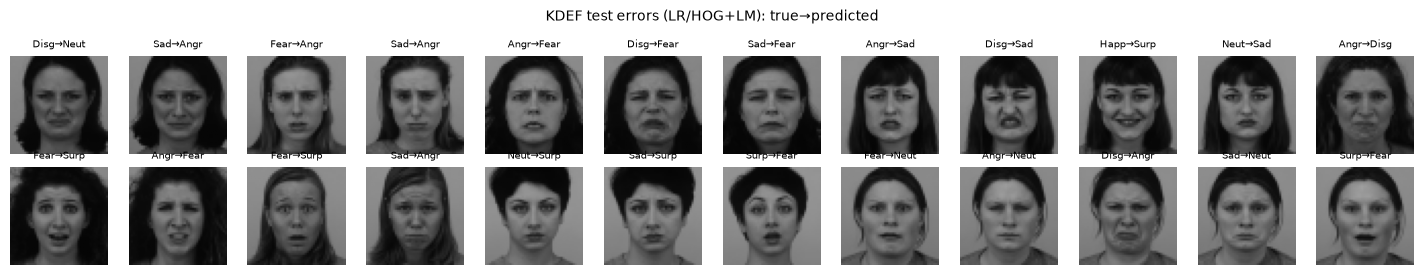

              precision    recall  f1-score   support

       Angry      0.636     0.500     0.560        28
     Disgust      0.739     0.607     0.667        28
        Fear      0.382     0.464     0.419        28
       Happy      0.964     0.964     0.964        28
         Sad      0.600     0.429     0.500        28
    Surprise      0.550     0.786     0.647        28
     Neutral      0.690     0.714     0.702        28

    accuracy                          0.638       196
   macro avg      0.652     0.638     0.637       196
weighted avg      0.652     0.638     0.637       196



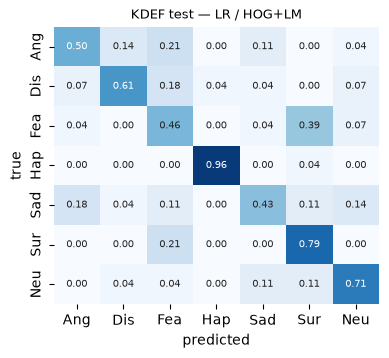

In [12]:
X_te_img = images(KEY, "test")[0]
wrong = np.where(p_best != y_te)[0]
show_images(X_te_img[wrong[:24]], [f"{EMO[y_te[i]][:4]}→{EMO[p_best[i]][:4]}" for i in wrong[:24]], ncols=12, size=1.2,
            suptitle=f"KDEF test errors ({BEST_MODEL}/{BEST_FEAT}): true→predicted", fname="task2_errors.png")
print(classification_report(y_te, p_best, target_names=EMO, digits=3))
plot_cm(y_te, p_best, f"KDEF test — {BEST_MODEL} / {BEST_FEAT}"); plt.savefig(FIG_DIR / "task2_best_cm.png"); plt.show()

## 7. Geometric features for the fuzzy classifier (Task 4) and the creative challenge
Computed here (dlib lives in this environment) and stored for the fuzzy environment.

In [13]:
geo = {"names": np.array(F.GEO_NAMES)}
for key, split, short in [(KEY, "train", "kdef_train"), (KEY, "test", "kdef_test"),
                          ("fer_gray", "train", "fer_train"), ("fer_gray", "test", "fer_test")]:
    geo[f"X_{short}"] = features(key, split, "GEO")
    geo[f"y_{short}"] = images(key, split)[1]
geo["subj_kdef_train"] = groups
np.savez_compressed(F.CACHE_DIR / "geo_features.npz", **geo)
g = pd.DataFrame(geo["X_kdef_train"], columns=F.GEO_NAMES).groupby(np.array(EMO)[geo["y_kdef_train"]]).mean()
save_table(g[["mouth_open", "mouth_width", "eye_open", "brow_height", "smile_ratio", "brow_distance"]], "task2_geo_class_means")
display(g.round(3))

,mouth_open,mouth_open_outer,mouth_width,mouth_aspect,smile_ratio,eye_open,brow_height,inner_brow_height,outer_brow_height,brow_distance,brow_slope,nose_to_mouth,jaw_drop,upper_lip_thickness,lower_lip_thickness,nostril_width,mouth_corner_to_eye,face_height,lip_corner_angle,chin_to_mouth
Angry,0.075,0.317,0.804,0.394,0.054,0.286,0.241,0.192,0.188,0.342,-0.037,0.221,1.850,0.091,0.159,0.464,1.190,2.310,-0.252,0.506
Disgust,0.136,0.372,0.870,0.428,0.077,0.232,0.250,0.212,0.176,0.386,0.010,0.184,1.869,0.086,0.152,0.496,1.105,2.161,-0.248,0.523
Fear,0.138,0.403,0.838,0.484,0.050,0.334,0.314,0.302,0.220,0.373,0.056,0.217,1.934,0.101,0.165,0.437,1.171,2.328,-0.350,0.511
Happy,0.195,0.386,1.104,0.350,0.162,0.240,0.287,0.265,0.189,0.409,0.048,0.159,1.856,0.067,0.126,0.502,0.946,1.690,-0.058,0.536
Neutral,0.037,0.285,0.809,0.352,0.022,0.314,0.298,0.271,0.212,0.379,0.034,0.229,1.831,0.098,0.156,0.419,1.138,2.267,-0.290,0.536
Sad,0.060,0.300,0.838,0.360,0.040,0.291,0.303,0.292,0.204,0.350,0.064,0.217,1.868,0.094,0.152,0.457,1.149,2.244,-0.259,0.527
Surprise,0.193,0.479,0.760,0.634,0.050,0.383,0.361,0.340,0.262,0.422,0.045,0.228,1.971,0.109,0.178,0.393,1.221,2.604,-0.460,0.466


## 8. Summary (auto-generated)

In [14]:
print(f"Best KDEF configuration (CV): {BEST_MODEL} + {BEST_FEAT}; test macro-F1 {f1_score(y_te, p_best, average='macro'):.3f}, "
      f"acc {accuracy_score(y_te, p_best):.3f}")
print("Mean test macro-F1 per classifier — FER:", fer_f1.mean(axis=1).round(3).to_dict(), " KDEF:", kdef_f1.mean(axis=1).round(3).to_dict())
print("Mean test macro-F1 per feature    — FER:", fer_f1.mean(axis=0).round(3).to_dict(), " KDEF:", kdef_f1.mean(axis=0).round(3).to_dict())
print("Per-class F1 gain on KDEF:", emo_cmp["difference"].round(3).to_dict())

Best KDEF configuration (CV): LR + HOG+LM; test macro-F1 0.637, acc 0.638
Mean test macro-F1 per classifier — FER: {'LR': 0.367, 'SVM': 0.52, 'RF': 0.466}  KDEF: {'LR': 0.65, 'SVM': 0.62, 'RF': 0.611}
Mean test macro-F1 per feature    — FER: {'HOG': 0.47, 'LM': 0.42, 'PCA': 0.415, 'HOG+LM': 0.498}  KDEF: {'HOG': 0.599, 'LM': 0.637, 'PCA': 0.631, 'HOG+LM': 0.64}
Per-class F1 gain on KDEF: {'Angry': 0.021, 'Disgust': -0.016, 'Fear': -0.077, 'Happy': 0.152, 'Sad': 0.033, 'Surprise': -0.049, 'Neutral': 0.201}


**Why KDEF is easier than FER2013** (to be supported with the numbers above): posed and
exaggerated expressions by trained actors; identical frontal pose, framing and studio lighting;
no occlusions, no label noise, no duplicates; perfectly balanced classes. The model only has to
separate expressions, not nuisance factors. **What makes KDEF harder:** only 784 training images
(high-variance estimates, few support vectors / weak forests), only 56 identities so the
person-specific face shape is a strong confounder (hence the subject-independent split), and the
196-image test set gives wide confidence intervals.